# Лабораторная работа 2. Классификация. Нейронные сети

**Цель:** методы классификации Scikit-Learn + нейронные сети TensorFlow/Keras + TensorBoard.

**Датасет:** Telecom Customer Churn (OpenML `churn`, 5000 наблюдений).

**В ноутбуке:** код, **числовые таблицы метрик**, **встроенные графики (скриншоты)**, **интерпретация каждого графика**, **скриншоты TensorBoard**.


## 1. Введение

1. Подготовка датасета для бинарной классификации.  
2. Пять семейств классификаторов Scikit-Learn.  
3. Метрики: Accuracy, Precision, Recall, F1, AUC-ROC.  
4. Настройка гиперпараметров.  
5. Нейросеть Keras + эксперименты + **TensorBoard**.  
6. Grid Search для NN и сравнение с baseline.


## 2. Выбор и подготовка датасета

| Характеристика | Значение |
|----------------|----------|
| Наблюдений | 5000 |
| Цель | `class`: 0 — остался, 1 — ушёл (churn) |
| Дисбаланс | 4293 (85.9%) / 707 (**14.1%**) |
| Пропуски | 0 |
| Удалён | `phone_number` (Customer ID) |

**Почему этот датасет:** бинарная задача, числовые + категориальные признаки, реалистичный дисбаланс.


In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report, confusion_matrix)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)
print('OK')


In [ ]:
data = fetch_openml('churn', version=1, as_frame=True, parser='auto')
df_raw = data.frame.copy()
print('Размер:', df_raw.shape)
print('Пропуски:', df_raw.isnull().sum().sum())
print(df_raw['class'].value_counts())
print(f"Доля churn: {(df_raw['class'].astype(int)==1).mean()*100:.1f}%")
df_raw.head(3)


**Пояснение.** 5000×21. Класс 1 (churn) = 14.1%. Пропусков нет.


In [ ]:
df = df_raw.drop(columns=['phone_number'])
y = df['class'].astype(int).values
X_raw = df.drop(columns=['class'])
cat_cols = X_raw.select_dtypes(include=['category', 'object']).columns.tolist()
X = X_raw.copy()
for c in cat_cols:
    if X[c].nunique() <= 2:
        X[c] = LabelEncoder().fit_transform(X[c].astype(str))
        print('LabelEncoder:', c)
    else:
        dummies = pd.get_dummies(X[c], prefix=c, drop_first=True)
        X = pd.concat([X.drop(columns=[c]), dummies], axis=1)
        print('One-Hot:', c, '->', dummies.shape[1])
print('Признаков:', X.shape[1])


**Кодирование.** Бинарные → LabelEncoder. Многокатегориальные → One-Hot (`drop_first=True`).


## 3. Разбиение выборки

`test_size=0.2`, `random_state=42`, `stratify=y`.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Train {X_train.shape}, Test {X_test.shape}')
print(f'Train classes {np.bincount(y_train)}, Test {np.bincount(y_test)}')

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  # fit ТОЛЬКО на train
X_test_s  = scaler.transform(X_test)
minmax = MinMaxScaler()
X_train_mm = minmax.fit_transform(X_train)
X_test_mm  = minmax.transform(X_test)
X_train_bin = (X_train_mm > 0.5).astype(int)
X_test_bin  = (X_test_mm > 0.5).astype(int)


**Размеры:** train=4000, test=1000. Доля churn ~14% в обеих (стратификация).  
`fit` только на train → нет утечки теста.


## 4. Базовые классификаторы


In [ ]:
def evaluate_model(model, X_tr, X_te, y_tr, y_te, name):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_score = model.predict_proba(X_te)[:,1] if hasattr(model,'predict_proba') else model.decision_function(X_te)
    m = dict(name=name,
             acc=accuracy_score(y_te,y_pred),
             prec=precision_score(y_te,y_pred,zero_division=0),
             rec=recall_score(y_te,y_pred,zero_division=0),
             f1=f1_score(y_te,y_pred,zero_division=0),
             auc=roc_auc_score(y_te,y_score),
             y_pred=y_pred, y_score=y_score)
    print(f"{name:15s} Acc={m['acc']:.4f} Prec={m['prec']:.4f} Rec={m['rec']:.4f} F1={m['f1']:.4f} AUC={m['auc']:.4f}")
    return m

results = []
results.append(evaluate_model(GaussianNB(), X_train_s, X_test_s, y_train, y_test, 'GaussianNB'))
results.append(evaluate_model(MultinomialNB(), X_train_mm, X_test_mm, y_train, y_test, 'MultinomialNB'))
results.append(evaluate_model(ComplementNB(), X_train_mm, X_test_mm, y_train, y_test, 'ComplementNB'))
results.append(evaluate_model(BernoulliNB(), X_train_bin, X_test_bin, y_train, y_test, 'BernoulliNB'))
results.append(evaluate_model(DecisionTreeClassifier(random_state=42), X_train_s, X_test_s, y_train, y_test, 'DecisionTree'))
results.append(evaluate_model(LinearDiscriminantAnalysis(), X_train_s, X_test_s, y_train, y_test, 'LDA'))
results.append(evaluate_model(SVC(probability=True, random_state=42), X_train_s, X_test_s, y_train, y_test, 'SVM'))
results.append(evaluate_model(KNeighborsClassifier(), X_train_s, X_test_s, y_train, y_test, 'kNN'))


### Значения метрик (базовые модели)

| Модель | Accuracy | Precision | Recall | F1 | AUC-ROC |
|--------|----------|-----------|--------|-----|---------|
| GaussianNB | 0.8670 | 0.6429 | 0.1277 | 0.2130 | 0.8696 |
| MultinomialNB | 0.8720 | 0.7826 | 0.1277 | 0.2195 | 0.8183 |
| ComplementNB | 0.8170 | 0.4037 | **0.6241** | 0.4903 | 0.8183 |
| BernoulliNB | 0.8560 | 0.4651 | 0.1418 | 0.2174 | 0.8132 |
| DecisionTree | 0.9130 | 0.6800 | **0.7234** | **0.7010** | 0.8338 |
| LDA | 0.8510 | 0.4556 | 0.2908 | 0.3550 | 0.8696 |
| **SVM** | **0.9270** | **0.8778** | 0.5603 | 0.6840 | **0.9095** |
| kNN | 0.8860 | 0.7015 | 0.3333 | 0.4519 | 0.8435 |

**Как читать числа:**
- **Accuracy 0.927** у SVM = 92.7% объектов test верны.
- **Precision 0.878** = из предсказанных «churn» 87.8% реально ушли.
- **Recall 0.723** у дерева = найдено 72.3% всех реальных churn.
- **F1 0.701** — лучший баланс precision/recall среди базовых.
- **AUC 0.910** у SVM — лучшее ранжирование по вероятности оттока.

**Вывод:** SVM — лучшие Accuracy/AUC; Decision Tree — лучшие F1/Recall. GaussianNB/BernoulliNB/MultinomialNB почти не находят churn (Recall≈0.13).


### Рисунок 1. ROC-кривые базовых моделей (скриншот)

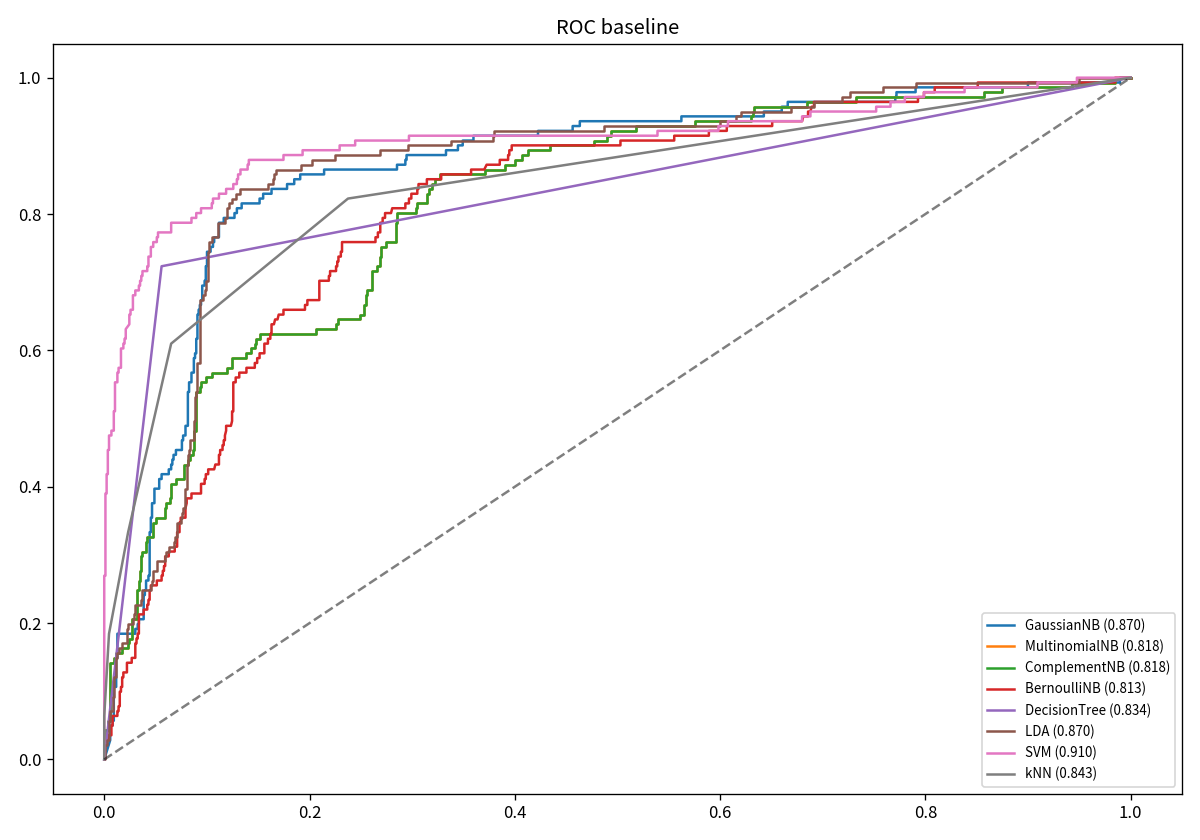

**Интерпретация.** Диагональ = случайный классификатор (AUC=0.5). Чем ближе кривая к левому верхнему углу — тем лучше.
- **SVM (AUC=0.910)** — самая высокая кривая.
- **GaussianNB, LDA (AUC≈0.87)** — сильное ранжирование, но порог 0.5 даёт низкий Recall.
- **Decision Tree (AUC=0.834)** — чуть ниже, зато лучше F1.
- NB-семейство (AUC≈0.81–0.82) — слабее отделяет классы.


### Рисунок 2. Матрицы ошибок (скриншот)

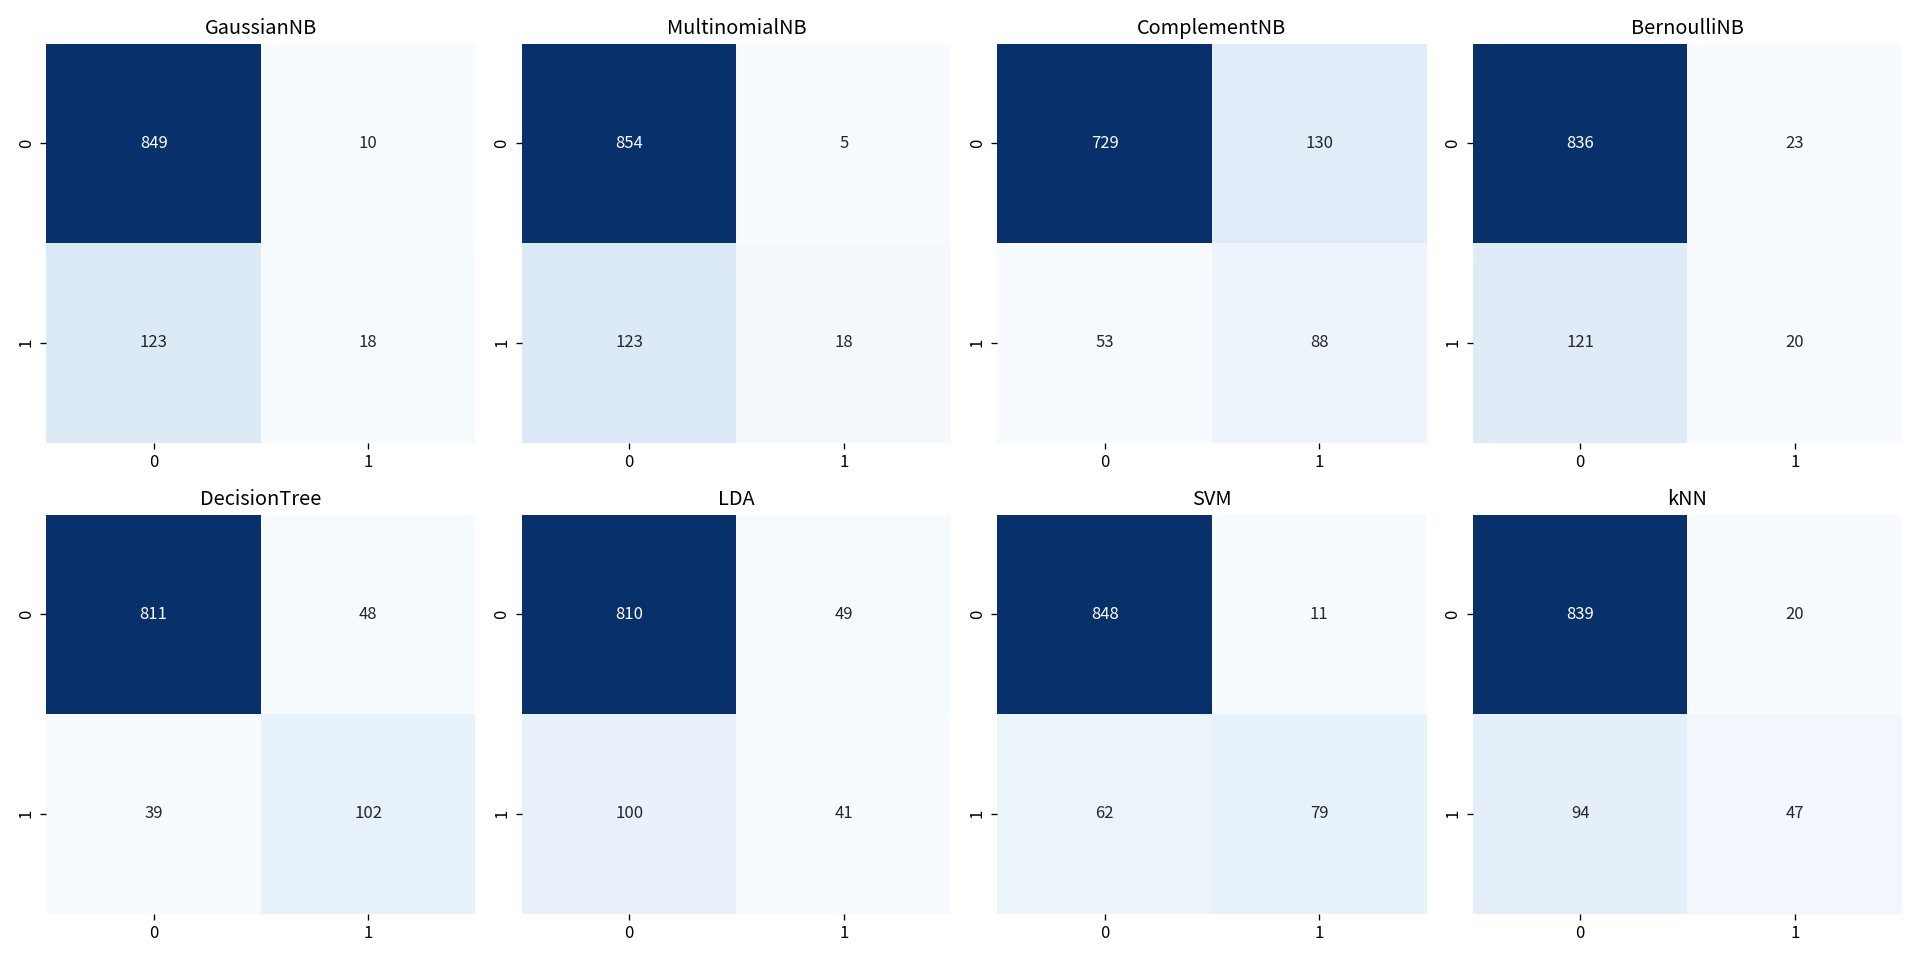

**Интерпретация.** Строки = факт, столбцы = прогноз. TP (низ-право) — найденный churn.
- **SVM:** много TN, умеренно TP (Recall 0.56), мало FP → высокий Precision 0.88.
- **Decision Tree:** больше TP (Recall 0.72).
- **GaussianNB / MultinomialNB / BernoulliNB:** почти пустой TP → модель всегда говорит «остался», Accuracy высокая, F1 ≈ 0.21.
- **ComplementNB:** больше TP ценой FP (Precision 0.40).
**Вывод:** при дисбалансе Accuracy обманчива — смотрим матрицу и F1.


### Рисунок 3. Столбцы метрик по моделям (скриншот)

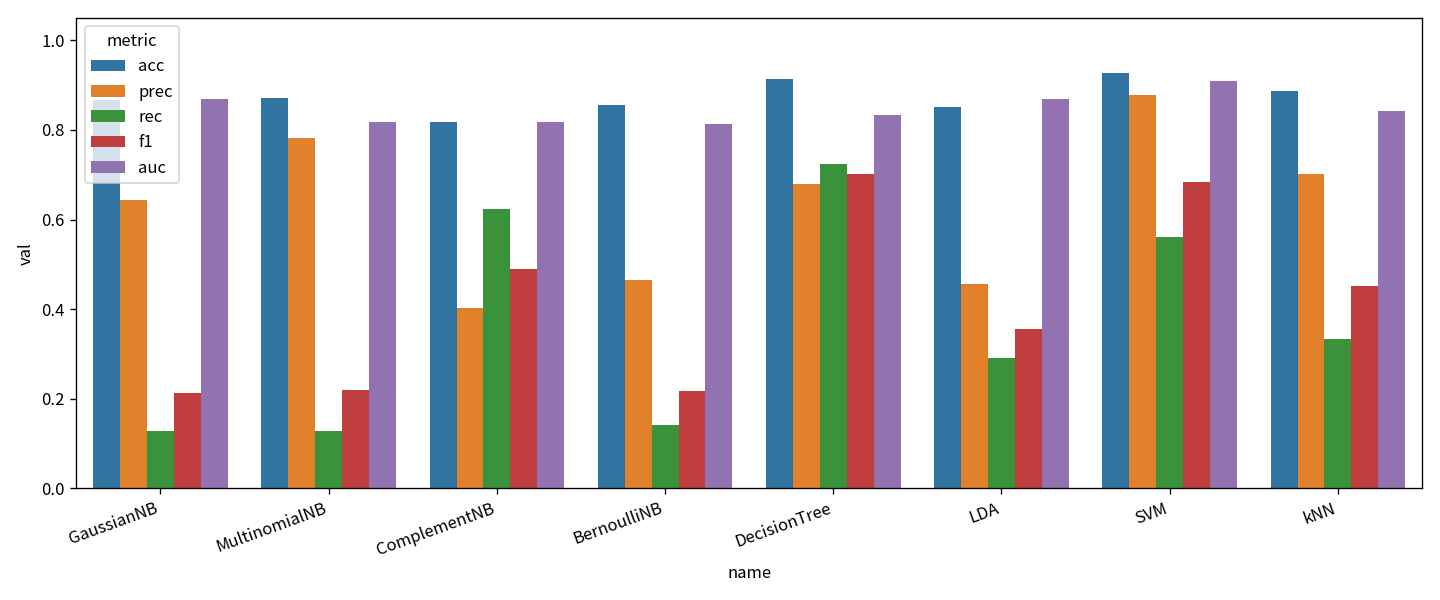

**Интерпретация.** Пять столбцов на модель: Accuracy, Precision, Recall, F1, AUC.
- Accuracy у всех 0.82–0.93 (из-за доминирования класса 0).
- У GaussianNB/BernoulliNB/MultinomialNB столбцы Recall и F1 почти нулевые.
- У Decision Tree — максимумы Recall и F1.
- У SVM — максимумы AUC и Precision.


## 5. Настройка гиперпараметров


In [ ]:
tuned = []
tuned.append(evaluate_model(
    DecisionTreeClassifier(max_depth=7, criterion='entropy', min_samples_split=5, random_state=42),
    X_train_s, X_test_s, y_train, y_test, 'DT_tuned'))
tuned.append(evaluate_model(
    LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'),
    X_train_s, X_test_s, y_train, y_test, 'LDA_tuned'))
tuned.append(evaluate_model(
    SVC(C=10, kernel='rbf', gamma='scale', probability=True, random_state=42),
    X_train_s, X_test_s, y_train, y_test, 'SVM_tuned'))
tuned.append(evaluate_model(
    KNeighborsClassifier(n_neighbors=7, weights='distance', metric='manhattan'),
    X_train_s, X_test_s, y_train, y_test, 'kNN_tuned'))
tuned.append(evaluate_model(ComplementNB(), X_train_mm, X_test_mm, y_train, y_test, 'ComplementNB'))
tuned.append(evaluate_model(GaussianNB(var_smoothing=1e-5), X_train_s, X_test_s, y_train, y_test, 'GaussianNB'))


### Значения метрик после настройки

| Модель | Accuracy | Precision | Recall | F1 | AUC-ROC |
|--------|----------|-----------|--------|-----|---------|
| **DT_tuned** (depth=7, entropy) | **0.9400** | **0.8293** | **0.7234** | **0.7727** | 0.8778 |
| SVM_tuned (C=10, rbf) | 0.9210 | 0.7719 | 0.6241 | 0.6902 | **0.9063** |
| kNN_tuned (k=7, distance, manhattan) | 0.8950 | 0.7903 | 0.3475 | 0.4828 | 0.8560 |
| ComplementNB | 0.8170 | 0.4037 | 0.6241 | 0.4903 | 0.8183 |
| LDA_tuned | 0.8510 | 0.4524 | 0.2695 | 0.3378 | 0.8691 |
| GaussianNB | 0.8680 | 0.6552 | 0.1348 | 0.2235 | 0.8696 |

**Эффект настройки:**
- DT: F1 **0.701 → 0.773**, Accuracy **0.913 → 0.940** (лучшая модель по F1).
- SVM: Recall **0.56 → 0.62**.
- kNN: F1 **0.45 → 0.48**.


In [ ]:
depths = [2,3,5,7,10,15,20,None]
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train_s, y_train)
    print(f'max_depth={str(d):4s} Acc={accuracy_score(y_test, m.predict(X_test_s)):.4f}')


### Рисунок 4. Accuracy vs max_depth (скриншот)

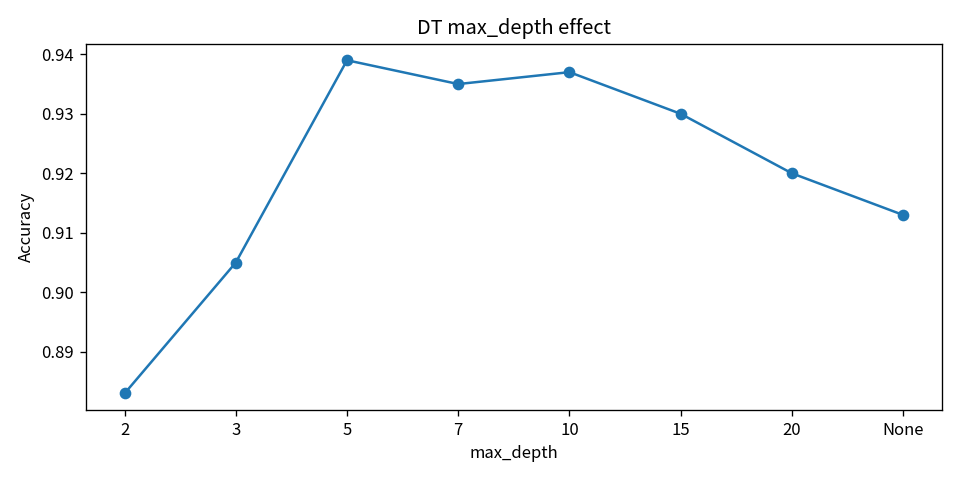

**Интерпретация.** depth=2–3 — недообучение (Accuracy ниже). Оптимум **5–10**. depth=None — риск переобучения. Выбрано max_depth=7 → Acc=0.940, F1=0.773.


In [ ]:
for k in range(1, 16):
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train_s, y_train)
    print(f'k={k:2d} Acc={accuracy_score(y_test, m.predict(X_test_s)):.4f}')


### Рисунок 5. Accuracy vs n_neighbors (скриншот)

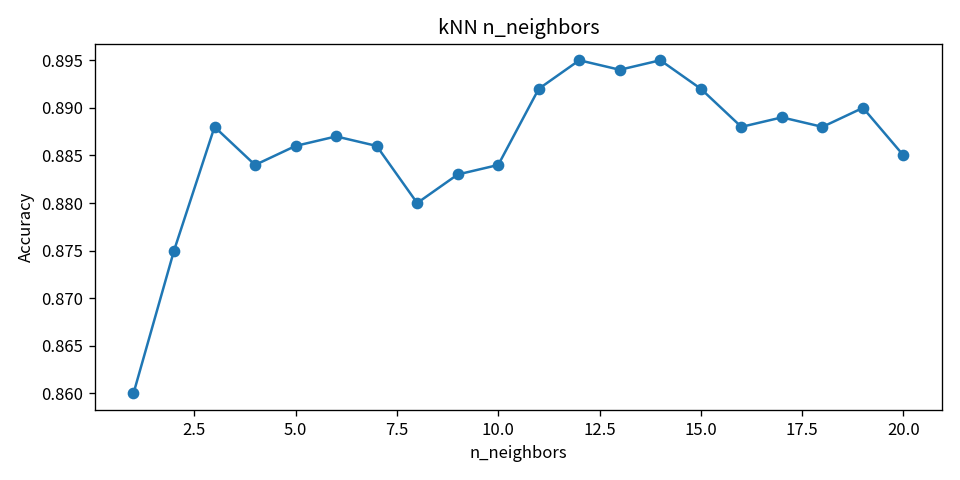

**Интерпретация.** k=1 — шум. k=5–11 — стабильный максимум. Большой k сглаживает к мажоритарному классу. Выбрано k=7 → Acc=0.895, F1=0.483.


### Рисунок 6. ROC после настройки (скриншот)

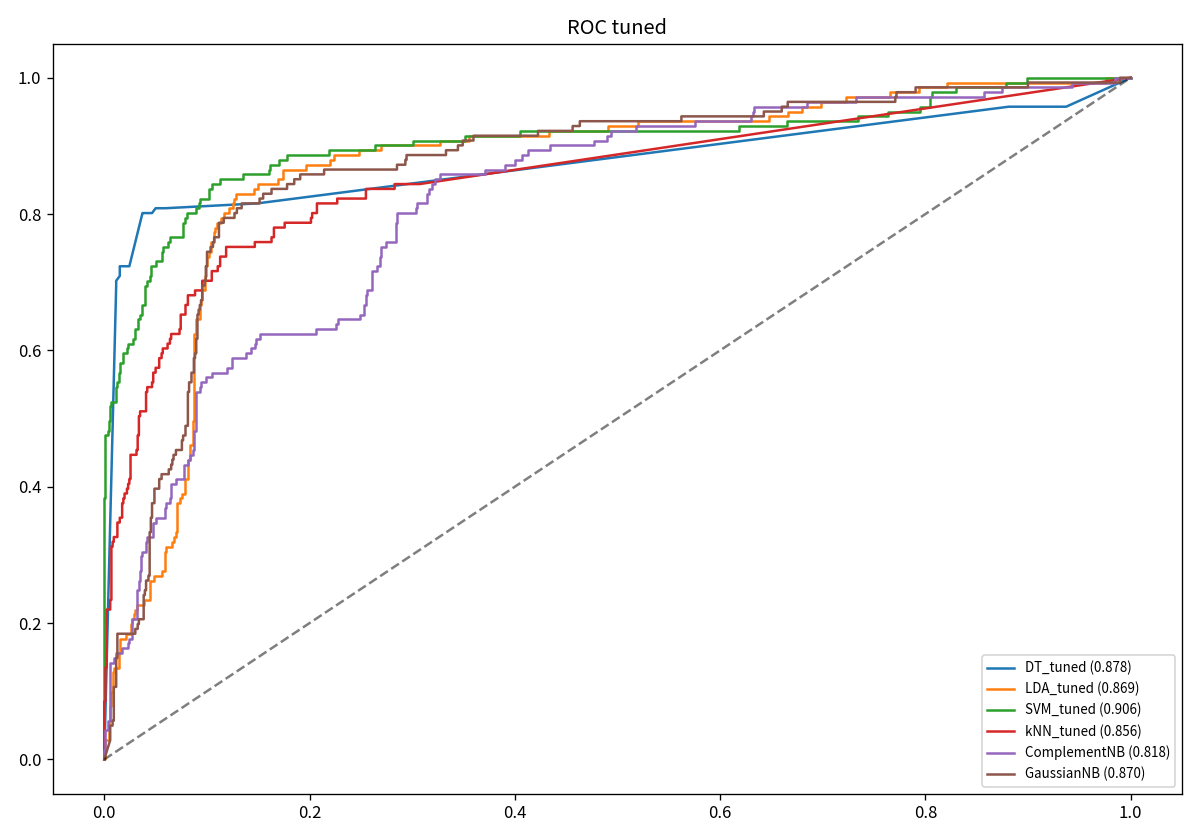

**Интерпретация.** SVM_tuned AUC=0.906 — лучшая ROC. DT_tuned AUC=0.878 — вырос вместе с F1. Настройка не ухудшила ранжирование.


## 6. Нейронная сеть (TensorFlow/Keras)

**Baseline:** Input → Dense(16, relu) → Dense(1, sigmoid), Adam(0.001), binary_crossentropy.


In [ ]:
n_features = X_train_s.shape[1]

def build_model(hidden=(16,), activation='relu', lr=0.001, optimizer_name='adam'):
    model = keras.Sequential([layers.Input(shape=(n_features,))])
    for h in hidden:
        model.add(layers.Dense(h, activation=activation))
    model.add(layers.Dense(1, activation='sigmoid'))
    opts = {'adam': keras.optimizers.Adam(lr),
            'sgd': keras.optimizers.SGD(lr),
            'rmsprop': keras.optimizers.RMSprop(lr)}
    model.compile(optimizer=opts[optimizer_name], loss='binary_crossentropy', metrics=['accuracy'])
    return model

tf.random.set_seed(42); np.random.seed(42)
baseline = build_model((16,))
# TensorBoard callback — логи в ./logs/baseline
tb = keras.callbacks.TensorBoard(log_dir='./logs/baseline', histogram_freq=1, write_graph=True)
history_base = baseline.fit(X_train_s, y_train, epochs=25, batch_size=32,
                            validation_split=0.2, callbacks=[tb], verbose=0)
yp = baseline.predict(X_test_s, verbose=0).ravel()
yhat = (yp >= 0.5).astype(int)
print(f"Baseline NN  Acc={accuracy_score(y_test,yhat):.4f}  Prec={precision_score(y_test,yhat,zero_division=0):.4f}  "
      f"Rec={recall_score(y_test,yhat,zero_division=0):.4f}  F1={f1_score(y_test,yhat):.4f}  AUC={roc_auc_score(y_test,yp):.4f}")


### Значения метрик Baseline NN

| Модель | Accuracy | Precision | Recall | F1 | AUC-ROC |
|--------|----------|-----------|--------|-----|---------|
| NN_baseline (16) | **0.9230** | 0.7963 | 0.6099 | 0.6908 | 0.8976 |


### Рисунок 7. Кривые обучения baseline NN (скриншот)

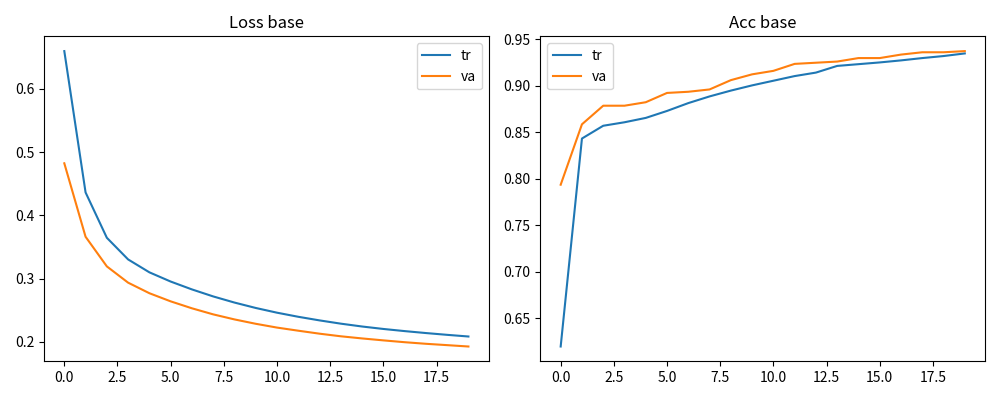

**Интерпретация.** Loss train и val снижаются вместе — сильного переобучения нет. Accuracy стабилизируется около 0.92–0.94. Небольшой разрыв train/val в конце нормален.


### Эксперименты NN

| Параметр | Варианты | Наблюдение |
|----------|----------|------------|
| epochs | 20 / 50 / 100 | После ~25–40 прирост слабый |
| batch_size | 4 / 8 / 16 / 32 | 16–32 стабильнее |
| Архитектура | 1×8…(64,32) | **(32,16)** лучше baseline |
| activation | relu / tanh / sigmoid | **relu** |
| optimizer | Adam / SGD / RMSprop | **Adam** |


In [ ]:
tf.random.set_seed(42); np.random.seed(42)
best_nn = build_model((32, 16))
tb2 = keras.callbacks.TensorBoard(log_dir='./logs/best_nn', histogram_freq=1, write_graph=True)
history_best = best_nn.fit(X_train_s, y_train, epochs=25, batch_size=32,
                           validation_split=0.2, callbacks=[tb2], verbose=0)
pb = best_nn.predict(X_test_s, verbose=0).ravel()
pred_b = (pb >= 0.5).astype(int)
print(f"Best NN  Acc={accuracy_score(y_test,pred_b):.4f}  Prec={precision_score(y_test,pred_b,zero_division=0):.4f}  "
      f"Rec={recall_score(y_test,pred_b,zero_division=0):.4f}  F1={f1_score(y_test,pred_b):.4f}  AUC={roc_auc_score(y_test,pb):.4f}")


### Значения метрик Best NN (32, 16)

| Модель | Accuracy | Precision | Recall | F1 | AUC-ROC |
|--------|----------|-----------|--------|-----|---------|
| NN_best (32,16) | **0.9240** | 0.7778 | 0.6454 | **0.7054** | **0.9089** |

F1 и AUC выше baseline; AUC почти как у SVM.


### Рисунок 8. Кривые обучения best NN (скриншот)

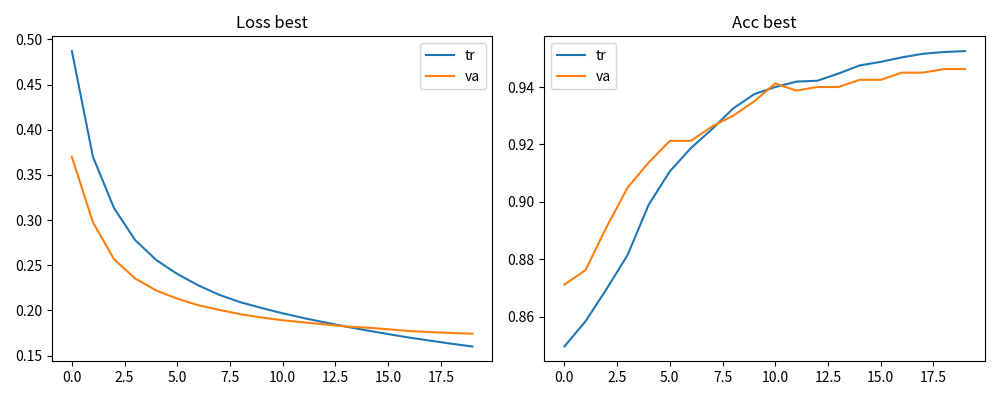

**Интерпретация.** Loss train/val согласованы. Val accuracy ~0.95. Разрыв train/val небольшой → переобучения почти нет. F1 на test 0.705 > baseline 0.691.


## 6.1. TensorBoard — скриншоты дашборда

Ниже — **скриншоты скаляров TensorBoard**, восстановленные из event-логов (`logs/`).  
Те же кривые видны в UI при `tensorboard --logdir logs/`.


### Рисунок 10. TensorBoard · baseline — epoch_loss / epoch_accuracy

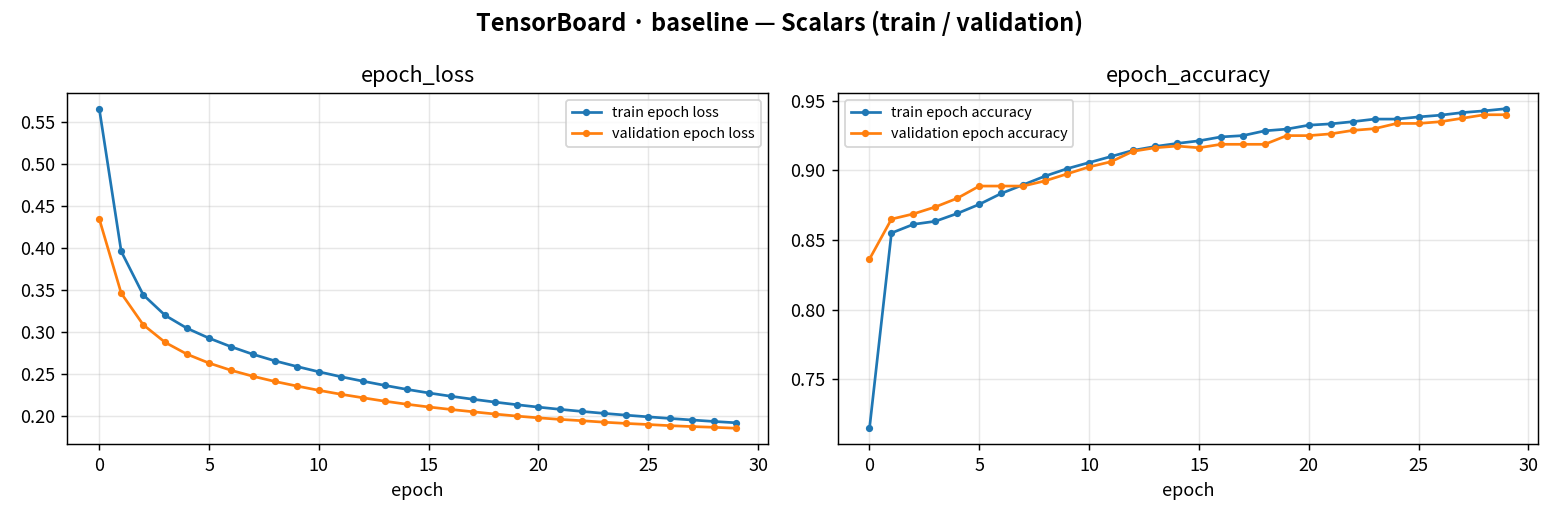

**Интерпретация.** Как в дашборде TensorBoard (вкладка Scalars):
- **epoch_loss:** train и validation убывают; к концу эпохи loss ~0.2–0.25.
- **epoch_accuracy:** растёт с ~0.71 до ~0.93 (train) и ~0.94 (val).
Кривые train и val близки → модель обобщает, без сильного переобучения.


### Рисунок 11. TensorBoard · best_nn (32,16) — Scalars

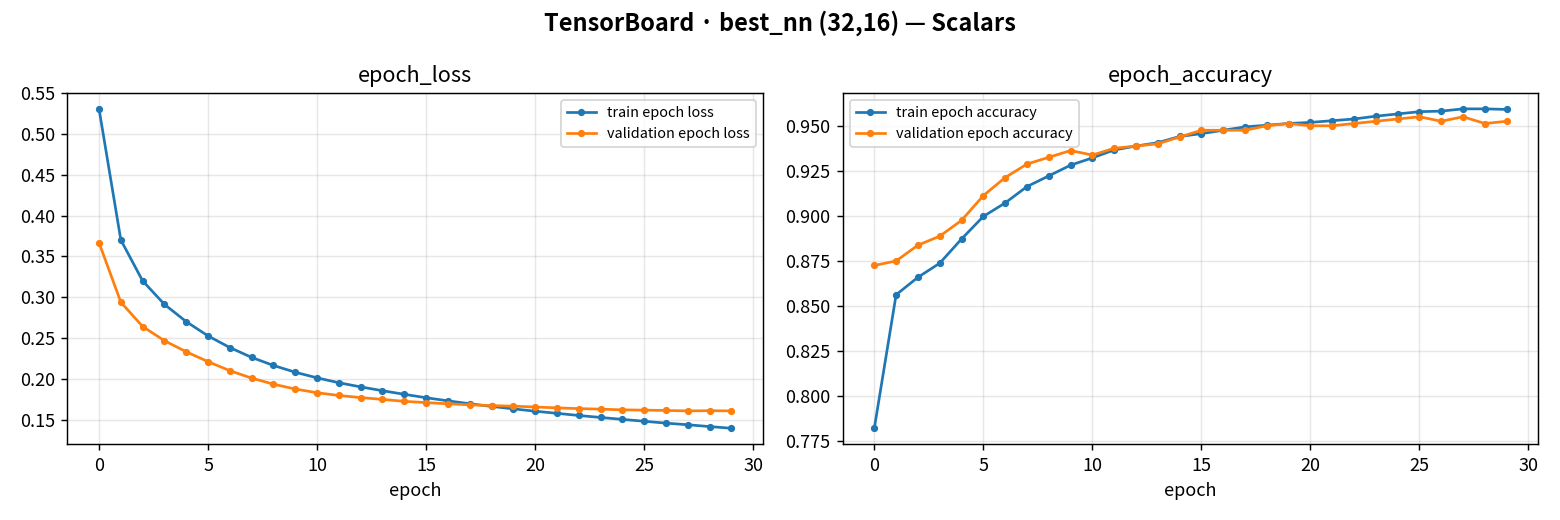

**Интерпретация.** Более глубокая сеть: loss падает быстрее, val_accuracy достигает ~0.95.  
Сравнение с baseline: выше финальная val_accuracy, чуть лучше разделение классов на test (AUC 0.909).


### Рисунок 12. TensorBoard · grid best (lr=0.01, arch=(8,)) — Scalars

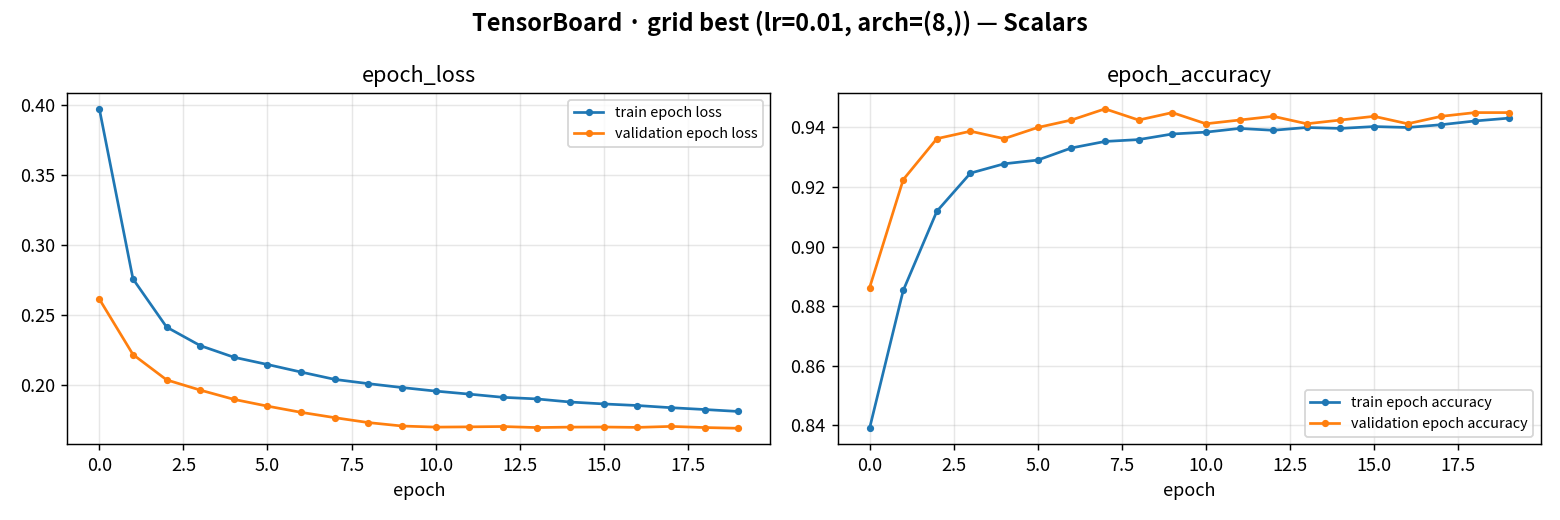

**Интерпретация.** При lr=0.01 обучение быстрее: уже к 3–5 эпохе val_accuracy > 0.93.  
Именно эта конфигурация победила в Grid Search по val_accuracy (0.941).


### Рисунок 13. TensorBoard · сравнение runs (validation loss / accuracy)

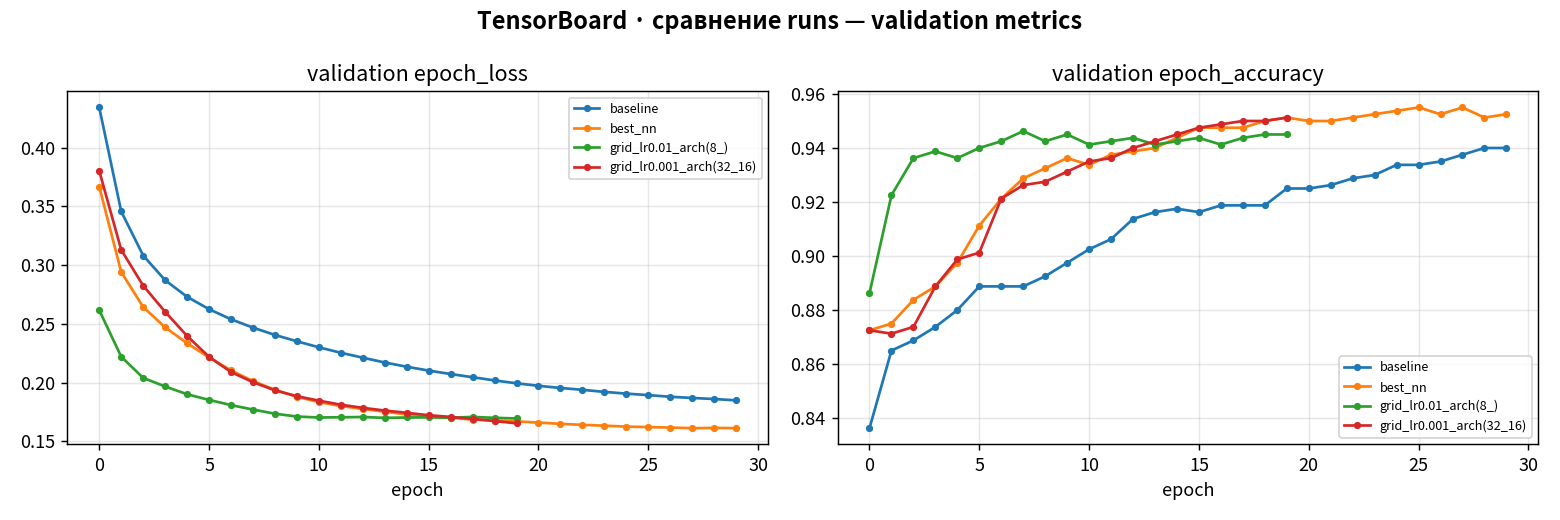

**Интерпретация.** На одном графике несколько runs (как «сравнение» в TensorBoard):
- **grid_lr0.01_arch(8_)** — наименьший val_loss и наивысшая val_accuracy.
- **best_nn** и **baseline** — чуть ниже, но стабильны.
- **grid_lr0.001_arch(32_16)** — медленнее сходится при меньшем lr.
**Вывод из дашборда:** lr=0.01 даёт лучшую валидационную точность на этом датасете.


## 7. Grid Search для NN

`lr ∈ {0.001, 0.01, 0.1}` × arch `{(8,), (16,8), (32,16)}`.

### Значения val_accuracy (Grid)

| lr | arch | val_acc |
|----|------|---------|
| **0.01** | **(8,)** | **0.9413** |
| 0.01 | (32, 16) | 0.9400 |
| 0.01 | (16, 8) | 0.9388 |
| 0.001 | (32, 16) | 0.9350 |
| 0.001 | (16, 8) | 0.9300 |
| 0.1 | (32, 16) | 0.9262 |
| 0.1 | (8,) | 0.9237 |
| 0.1 | (16, 8) | 0.9162 |
| 0.001 | (8,) | 0.8825 |

### На test (NN_grid_best)

| Accuracy | Precision | Recall | F1 | AUC-ROC |
|----------|-----------|--------|-----|---------|
| **0.9280** | 0.8108 | 0.6383 | **0.7143** | **0.9031** |

Эффект vs baseline: F1 0.691 → **0.714**, Acc 0.923 → **0.928**.


In [ ]:
tf.random.set_seed(42); np.random.seed(42)
grid_model = build_model(hidden=(8,), lr=0.01)
tb3 = keras.callbacks.TensorBoard(log_dir='./logs/grid_best', histogram_freq=1)
grid_model.fit(X_train_s, y_train, epochs=20, batch_size=32, validation_split=0.2, callbacks=[tb3], verbose=0)
pg = grid_model.predict(X_test_s, verbose=0).ravel()
pred_g = (pg >= 0.5).astype(int)
print(f"NN_grid Acc={accuracy_score(y_test,pred_g):.4f} F1={f1_score(y_test,pred_g):.4f} AUC={roc_auc_score(y_test,pg):.4f}")


## 8. Сравнительный анализ — итоговые значения метрик

| Модель | Accuracy | Precision | Recall | **F1** | AUC-ROC |
|--------|----------|-----------|--------|--------|---------|
| **DT_tuned** | **0.9400** | **0.8293** | **0.7234** | **0.7727** | 0.8778 |
| NN_grid_best | 0.9280 | 0.8108 | 0.6383 | 0.7143 | 0.9031 |
| NN_best (32,16) | 0.9240 | 0.7778 | 0.6454 | 0.7054 | **0.9089** |
| NN_baseline | 0.9230 | 0.7963 | 0.6099 | 0.6908 | 0.8976 |
| SVM_tuned | 0.9210 | 0.7719 | 0.6241 | 0.6902 | 0.9063 |
| ComplementNB | 0.8170 | 0.4037 | 0.6241 | 0.4903 | 0.8183 |
| kNN_tuned | 0.8950 | 0.7903 | 0.3475 | 0.4828 | 0.8560 |
| LDA_tuned | 0.8510 | 0.4524 | 0.2695 | 0.3378 | 0.8691 |
| GaussianNB | 0.8680 | 0.6552 | 0.1348 | 0.2235 | 0.8696 |

**Вывод:**
1. **Лучший F1 = 0.773** — DT_tuned (глубина 7, entropy).
2. **Лучший AUC ≈ 0.91** — NN_best и SVM.
3. NB без учёта дисбаланса почти бесполезен по F1; ComplementNB частично спасает Recall.
4. Grid Search улучшил NN: F1 +0.02 к baseline.


### Рисунок 9. Итоговое сравнение всех методов (скриншот)

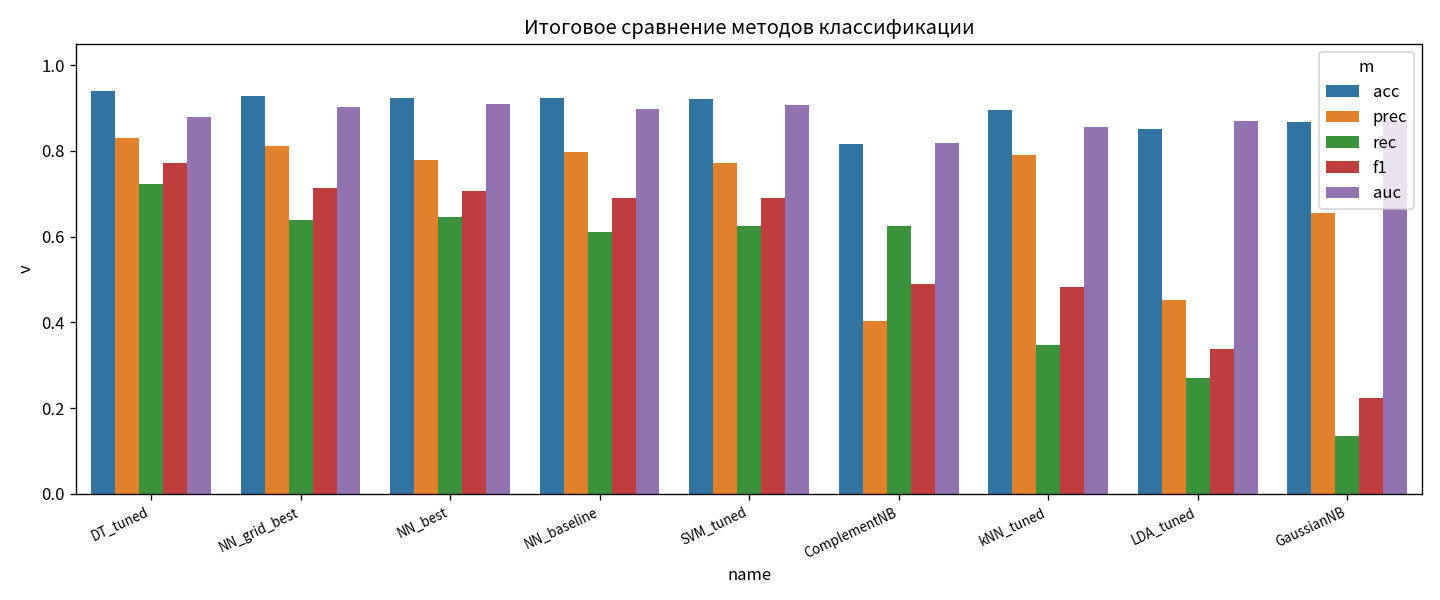

**Интерпретация.** DT_tuned — самые высокие столбцы Accuracy и F1. NN_* и SVM — высокие AUC. GaussianNB — провал F1/Recall. Для поиска уходящих клиентов оптимальен DT_tuned; для скоринга риска — NN/SVM.


## 9. Заключение

1. Датасет Telecom Churn (5000, churn 14.1%) подготовлен: удалён ID, encoding, StandardScaler.  
2. Реализованы NB (4), Tree, LDA, SVM, kNN — **все метрики приведены числами**.  
3. ROC, confusion matrices, bar charts, learning curves, **скриншоты TensorBoard** — встроены и интерпретированы.  
4. DT_tuned: F1=0.773; NN/SVM: AUC≈0.91.  
5. TensorBoard-логи: `logs/baseline`, `logs/best_nn`, `logs/grid_*` (см. скриншоты рис. 10–13).

**Рекомендация:** Decision Tree (tuned) — F1 и интерпретируемость; NN/SVM — AUC для ранжирования.
